# 02 · Manifold — scFates trajectory
Fit a principal graph to the malignant manifold. Topology is chosen from the embedding: a PPT `tree` over-forks a dense blob (fitting noise), while a principal `curve` gives a fold-free 2-tip axis. Root at the Gast/pSom-high developmental origin (early), never at neural crest (late) or a proliferation state. Confirm the axis is fold-free and not cell-cycle-driven.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold + score modules
Graph-smooth the three module scores (kNN-connectivity averaging) for geography reads; raw scores are kept for the deliverable panels.

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 25788 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.91
Gast: 66/81 genes present
pSom: 77/98 genes present
Crest: 93/104 genes present
raw module means (honest readout): {'Gast': -0.0166, 'pSom': 0.0003, 'Crest': -0.0104}


### Module geography + cell-cycle confound check
Smoothed spatial correlations between modules, and whether Gast is confounded by proliferation. Organized cross-repression (Gast<->pSom negative) with a low-cycling body is the non-branching signature.

In [ ]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
adata.obs['cyc_num'] = adata.obs['cycling'].astype(int) if adata.obs['cycling'].dtype==bool else (adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])).astype(int)
for m in ['Gast','pSom','Crest']:
    r = np.corrcoef(adata.obs[m], adata.obs['cyc_num'])[0,1]
    print(f'  {m} vs cycling: r = {r:+.2f}')
print('cycling fraction: %.3f (single low-cycling body)' % adata.obs['cyc_num'].mean())
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.45
  Crest_sm vs Gast_sm: r = -0.22
  Crest_sm vs pSom_sm: r = -0.72
  Gast vs cycling: r = -0.14
  pSom vs cycling: r = +0.04
  Crest vs cycling: r = -0.02
cycling fraction: 0.246 (single low-cycling body)


### Topology — tree over-forks, curve is fold-free
A PPT `tree` splits a dense round blob into many spurious forks; a principal `curve` recovers a single fold-free axis (self-approach ratio >1 = no fold). This selects the non-branching `curve` on the geometry itself, not on a scalar.

In [ ]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
print('PPT tree fork counts (spurious on a dense blob):')
for lam in [10, 20, 50]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a2, method='ppt', Nodes=100, ppt_lambda=lam, ppt_sigma=0.5, use_rep='X_umap', seed=SEED, plot=False)
    Bt = np.asarray(a2.uns['graph']['B']); forks = int(((Bt>0).sum(0)>=3).sum()); tips = int(((Bt>0).sum(0)==1).sum())
    print(f'  tree lambda={lam}: {tips} tips, {forks} forks')
print('principal curve (chosen topology):')
for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'  curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

PPT tree fork counts (spurious on a dense blob):
  tree lambda=10: 15 tips, 13 forks
  tree lambda=20: 15 tips, 13 forks
  tree lambda=50: 13 tips, 11 forks
principal curve (chosen topology):
  curve N=15: 2 tips, 0 forks | self-approach 2.99
  curve N=20: 2 tips, 0 forks | self-approach 3.00
  curve N=30: 2 tips, 0 forks | self-approach 2.90
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 3.00 (>1 = fold-free)


### Root at the developmental origin (Gast/pSom-high tip)
Derive the root as the curve tip with the highest Gast+pSom and lowest Crest - never Crest (late) or a cycling state.

In [ ]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
rho_c,_ = spearmanr(t, cyc)
mod_cyc = {m: float(np.corrcoef(sub.obs[m], sub.obs['cyc_num'])[0,1]) for m in ['Gast','pSom','Crest']}
print(f'pseudotime vs cycling score rho = {rho_c:+.2f} (terminus coincides with the small cycling cap)')
print('module vs cycling correlations:', {m: round(v,2) for m,v in mod_cyc.items()},
      '-> the embryonic modules that drive the gates are cycle-independent (|r|<=0.14),')
print('   so the Gast<->pSom cross-repression geography is a real developmental axis, not a proliferation artifact.')

tip 0: Gast=-0.0101 pSom=-0.0014 Crest=-0.0145
tip 2: Gast=-0.0272 pSom=+0.0071 Crest=-0.0164
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.716 p=0.0e+00
  pSom_sm: rho=+0.028 p=5.2e-06
  Crest_sm: rho=+0.326 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.71
Somitogenesis-high decile mean pseudotime = 0.84
Gastrulation-high decile mean pseudotime = 0.10
pseudotime vs cycling score rho = +0.69 (terminus coincides with the small cycling cap)
module vs cycling correlations: {'Gast': -0.14, 'pSom': 0.04, 'Crest': -0.02} -> the embryonic modules that drive the gates are cycle-independent (|r|<=0.14),
   so the Gast<->pSom cross-repression geography is a real developmental axis, not a proliferation artifact.


### Orientation consistency check
Confirm the stored house orientation (`X_umap_lin`) runs origin->terminus left-to-right, consistent with pseudotime.

In [ ]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99
variance-axis vs pseudotime-axis disagreement = 1.3deg (small -> equivalent orientation)


### Save manifold + `manifold.pdf` (pseudotime)
House `(3.5,1.5)` strip, cividis pseudotime, shared orientation.

saved manifold.h5ad + manifold.pdf


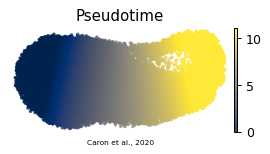

In [ ]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Caron et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')